# SEM attenuation · records with and without Q, and the constant-Q fit

The attenuating SEM classes take quality factors as models, next to the velocities and the
density, and approximate a constant Q over a frequency band with a few standard linear solids
(mechanisms). In 2-D:

| class | medium | models |
|---|---|---|
| `ViscoElasticVSSEM2DDeformed` | elastic, velocity-stress | `vp, vs, rho, Qp, Qs` |
| `ViscoElasticSEM2DDeformed` | elastic, displacement (SPECFEM2D's scheme) | `vp, vs, rho, Qk, Qmu` |
| `ViscoAcousticPotentialSEM2D` | acoustic | `vp, Qk` |

This notebook runs one record with and without attenuation in an elastic and in an acoustic
medium, and then shows how the mechanisms are fitted to a constant Q. The 3-D classes are in
[SEM visco-elastic attenuation in 3-D](../59_sem_visco_elastic3d/).

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt

from sweep.sem import (AcousticPotentialSEM2D, ElasticVSSEM2DDeformed, PropSEM,
                       ViscoAcousticPotentialSEM2D, ViscoElasticVSSEM2DDeformed)
from sweep.signal import ricker

device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

device: cuda


## 1. An elastic record

An explosion in a homogeneous rock (`vp` 3000 m/s, `vs` 1500 m/s), with the C-PML on every side
and receivers on a line from 200 m to 2.2 km from it. `ViscoElasticVSSEM2DDeformed` takes the
two quality factors as two more models, here `Qp = 30` and `Qs = 20`. `equation_options` sets
the frequency `f_ref` at which `vp` and `vs` are the phase velocities and the number of
mechanisms `n_sls`.

In [2]:
dh, dt, nt, f0 = 5.0, 4e-4, 2500, 15.0
shape = (161, 521)                                    # 0.8 km x 2.6 km
wavelet = ricker(np.arange(nt) * dt - 1.2 / f0, f=f0).astype(np.float32)
src = np.array([[40, 80]])                            # x = 200 m, z = 400 m
rx = np.arange(80, 481, 80)
rec = np.stack([rx, np.full_like(rx, 80)], axis=1)[None]
offsets = (rx - 40) * dh                              # 200 m to 2.2 km


def run(equation, values, **options):
    solver = PropSEM(equation, shape=shape, dh=dh, dt=dt, n_order=4, abcn=40,
                     f_dominant=f0, device=device, **options)
    models = [torch.full(shape, v, device=device) for v in values]
    with torch.no_grad():
        return solver(wavelet, src, rec, models=models)[0, :, :, 0].cpu().numpy()


elastic = dict(source_type=['sxx', 'szz'], receiver_type=['vx'])
lossless = run(ElasticVSSEM2DDeformed, (3000.0, 1500.0, 2400.0), **elastic)
lossy = run(ViscoElasticVSSEM2DDeformed, (3000.0, 1500.0, 2400.0, 30.0, 20.0),
            equation_options={'f_ref': f0, 'n_sls': 3}, **elastic)

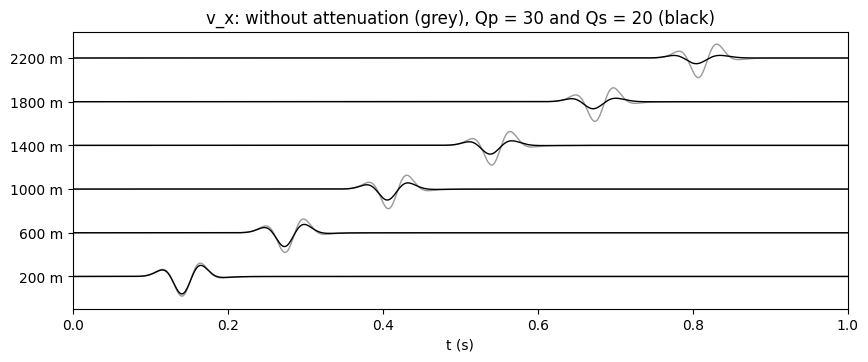

peak amplitude with Q over without: 0.89 0.70 0.56 0.45 0.36 0.29


In [3]:
def compare(a, b, title):
    # each receiver scaled by the peak of its record without attenuation
    t = np.arange(nt) * dt
    fig, ax = plt.subplots(figsize=(10, 3.6))
    for i in range(len(offsets)):
        s = 0.45 / np.abs(a[:, i]).max()
        ax.plot(t, i + s * a[:, i], color='0.6', lw=1)
        ax.plot(t, i + s * b[:, i], 'k', lw=1)
    ax.set_yticks(range(len(offsets)), [f'{x:.0f} m' for x in offsets])
    ax.set_xlim(0, 1.0); ax.set_xlabel('t (s)'); ax.set_title(title)
    plt.show()
    ratio = np.abs(b).max(axis=0) / np.abs(a).max(axis=0)
    print('peak amplitude with Q over without:', ' '.join(f'{r:.2f}' for r in ratio))


compare(lossless, lossy, 'v_x: without attenuation (grey), Qp = 30 and Qs = 20 (black)')

With attenuation the pulse loses amplitude with the distance it travels, down to 0.29 of the
lossless one at 2.2 km. It loses its high frequencies first, so it also grows longer.

## 2. An acoustic record

`ViscoAcousticPotentialSEM2D` is the acoustic potential class with an attenuating bulk modulus:
its models are `vp` and `Qk`, and the density is the constructor's `density`. The same
experiment with a pressure source, pressure receivers and `Qk = 30`:

sweep: torch.compile is compiling the ViscoAcousticPotentialSEM2D step for a 161x521 grid; the first call on each new grid size takes seconds to a few minutes (cached on disk for later runs). EagerOptions(use_compile=False) runs uncompiled instead.


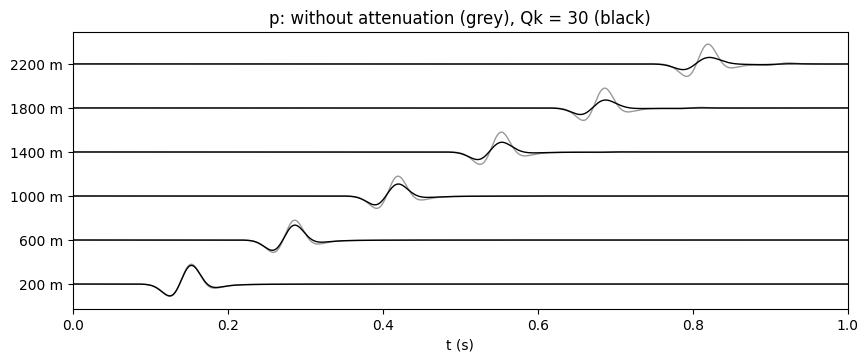

peak amplitude with Q over without: 0.94 0.75 0.61 0.49 0.40 0.33


In [4]:
lossless_p = run(AcousticPotentialSEM2D, (3000.0,))
lossy_p = run(ViscoAcousticPotentialSEM2D, (3000.0, 30.0), equation_options={'f_ref': f0})
compare(lossless_p, lossy_p, 'p: without attenuation (grey), Qk = 30 (black)')

The acoustic pulse attenuates as the elastic P wave does (0.33 at 2.2 km): the `Qk` of a fluid
is the Q of its P wave, and both are 30 here.

## 3. The constant-Q fit

Each class fits its mechanisms to a constant Q over a band, by default a factor of 12 around
`f_ref` for these two classes (`f_band` in `equation_options`). The default fit keeps the
mechanisms' relaxation times log-spaced over the band and fits their strengths;
`fit='nonlinear'` (on `ViscoAcousticPotentialSEM2D` and `ViscoElasticSEM2DDeformed`) fits the
relaxation times too, SPECFEM2D's `USE_SOLVOPT`. Below, the Q each fit realises for a target
`Q = 10` with three mechanisms:

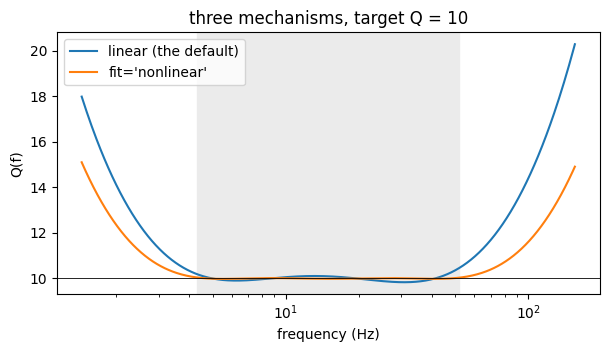

In [5]:
from sweep.equations.gsls_nonlinear import GSLSNonlinearFit
from sweep.equations.visco_elastic import GSLSFit, gsls_band, gsls_relaxation_times

band = gsls_band(f0)                                  # f0 / sqrt(12) to f0 * sqrt(12)
f = np.geomspace(band[0] / 3, band[1] * 3, 500)
tau = gsls_relaxation_times(3, *band)
fits = {'linear (the default)': (tau, GSLSFit(tau, *band).tau_np(10.0)),
        "fit='nonlinear'": GSLSNonlinearFit(3, *band, n_freq=200).params_np(10.0)}
plt.figure(figsize=(7, 3.4))
for name, (tau_l, w_l) in fits.items():
    m = GSLSNonlinearFit.modulus_ratio(tau_l, w_l, f)
    plt.semilogx(f, m.real / m.imag, label=name)
plt.axhline(10.0, color='k', lw=0.6)
plt.axvspan(*band, color='0.92', zorder=0)
plt.xlabel('frequency (Hz)'); plt.ylabel('Q(f)'); plt.title('three mechanisms, target Q = 10')
plt.legend(); plt.show()

Inside the band (shaded) both fits hold Q close to 10, the nonlinear one more closely. Outside
it Q rises, so the band should cover the frequencies of the wavelet.

## 4. Notes

- **Options** (`equation_options`): `f_ref`, `f_band`, `n_sls` and `velocities`, which says
  how `vp` and `vs` are read: the phase velocities at `f_ref` (`"phase"`, the default of the
  velocity-stress and acoustic classes), the real part of the modulus there
  (`"real_modulus"`), or the unrelaxed velocities (`"unrelaxed"`, the displacement class's
  default, as in SPECFEM2D).
- **Gradients.** The Q models are differentiable like the others. Boundary saving is refused,
  since the attenuation cannot be stepped back in time; use `Full()` or `Ckpt(chunks=...)`.
- **Backends.** `ViscoElasticVSSEM2DDeformed` runs on `impl='c'` and on eager; the other two
  classes on eager.
- **The absorbing layer** attenuates as the medium does, so the C-PML absorbs a lossy medium
  as well as a lossless one.
- **The time step** is limited by the unrelaxed velocities, which are higher than `vp` and `vs`
  for a low Q.

More in [Visco-elastic attenuation](../../user-guide/sem/#visco-elastic-attenuation) and
[Visco-acoustic attenuation](../../user-guide/sem/#visco-acoustic-attenuation).

---

<p><strong>Download this notebook</strong> &mdash; <a href="49_sem_attenuation.ipynb" download><code>49_sem_attenuation.ipynb</code></a> &middot; or <a href="https://github.com/DeepWave-KAUST/sweep/blob/dev/docs/notebooks/49_sem_attenuation.ipynb">view on GitHub</a></p>